# Medellin Elevation Filtration (10 Steps)

This notebook:
1. Loads `medellin_drive_with_elevation.graphml`
2. Builds a 10-step filtration by elevation percentiles (10% to 100%) from lowest to highest points
3. Plots every filtration step
4. Reports simple topological summaries (`beta0`, `beta1`) per step

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import osmnx as ox

%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)

In [3]:
graph_path = Path("data/medellin_drive_with_elevation.graphml")
if not graph_path.exists():
    raise FileNotFoundError(f"Graph file not found: {graph_path.resolve()}")

G = ox.load_graphml(graph_path)
print(f"Loaded graph: {graph_path}")
print(f"Nodes: {G.number_of_nodes():,} | Edges: {G.number_of_edges():,}")

Loaded graph: data/medellin_drive_with_elevation.graphml
Nodes: 15,207 | Edges: 36,725


In [4]:
def _to_float(value):
    if value is None:
        return np.nan
    try:
        return float(value)
    except (TypeError, ValueError):
        return np.nan

# Prefer elevation_m; fallback to elevation if needed
node_elev = {
    n: _to_float(data.get("elevation_m", data.get("elevation")))
    for n, data in G.nodes(data=True)
}

valid_nodes = [n for n, e in node_elev.items() if np.isfinite(e)]
if not valid_nodes:
    raise ValueError("No valid elevation attribute found on graph nodes.")

# Normalize attribute in-memory so all valid nodes have elevation_m as float
for n in valid_nodes:
    G.nodes[n]["elevation_m"] = float(node_elev[n])

valid_elev = np.array([node_elev[n] for n in valid_nodes], dtype=float)
missing = G.number_of_nodes() - len(valid_nodes)

print(f"Nodes with valid elevation: {len(valid_nodes):,}")
print(f"Nodes missing elevation: {missing:,}")
print(f"Elevation range (m): {valid_elev.min():.2f} to {valid_elev.max():.2f}")

Nodes with valid elevation: 15,207
Nodes missing elevation: 0
Elevation range (m): 1433.00 to 2104.00


In [5]:
def build_elevation_filtration(G, node_elev, n_steps=10):
    """
    Build filtration by elevation percentiles.
    Step k includes nodes with elevation <= percentile(k*10),
    and edges whose both endpoints are included (via induced subgraph).
    """
    if n_steps <= 0:
        raise ValueError("n_steps must be > 0")

    valid_nodes = [n for n, e in node_elev.items() if np.isfinite(e)]
    elev_values = np.array([node_elev[n] for n in valid_nodes], dtype=float)

    percentiles = np.linspace(100 / n_steps, 100, n_steps)
    thresholds = np.percentile(elev_values, percentiles)

    filtration = []
    for step, (pct, thr) in enumerate(zip(percentiles, thresholds), start=1):
        nodes_step = [n for n in valid_nodes if node_elev[n] <= thr]
        H = G.subgraph(nodes_step).copy()  # keeps edges with both endpoints in nodes_step

        # Simple undirected projection for beta summaries
        U = nx.Graph(H.to_undirected())
        U.remove_edges_from(nx.selfloop_edges(U))

        n_nodes = U.number_of_nodes()
        n_edges = U.number_of_edges()
        beta0 = nx.number_connected_components(U) if n_nodes > 0 else 0
        beta1 = n_edges - n_nodes + beta0 if n_nodes > 0 else 0

        filtration.append({
            "step": step,
            "percentile": float(pct),
            "threshold_m": float(thr),
            "graph": H,
            "nodes": set(nodes_step),
            "n_nodes": int(H.number_of_nodes()),
            "n_edges": int(H.number_of_edges()),
            "beta0": int(beta0),
            "beta1": int(beta1),
        })

    return filtration

filtration = build_elevation_filtration(G, node_elev=node_elev, n_steps=10)

summary_df = pd.DataFrame([
    {
        "step": f["step"],
        "percentile": f["percentile"],
        "threshold_m": f["threshold_m"],
        "nodes": f["n_nodes"],
        "edges": f["n_edges"],
        "beta0": f["beta0"],
        "beta1": f["beta1"],
    }
    for f in filtration
])

summary_df

,step,percentile,threshold_m,nodes,edges,beta0,beta1
0,1,10.0,1479.0,1569,2780,41,665
1,2,20.0,1494.0,3131,6300,44,1596
2,3,30.0,1507.0,4633,9760,37,2427
3,4,40.0,1523.0,6189,13436,31,3336
4,5,50.0,1546.0,7625,17031,25,4155
5,6,60.0,1577.6,9124,20865,33,4864
6,7,70.0,1622.0,10663,24813,18,5529
7,8,80.0,1673.0,12189,28949,20,6230
8,9,90.0,1744.0,13693,32824,17,6767
9,10,100.0,2104.0,15207,36725,1,7228


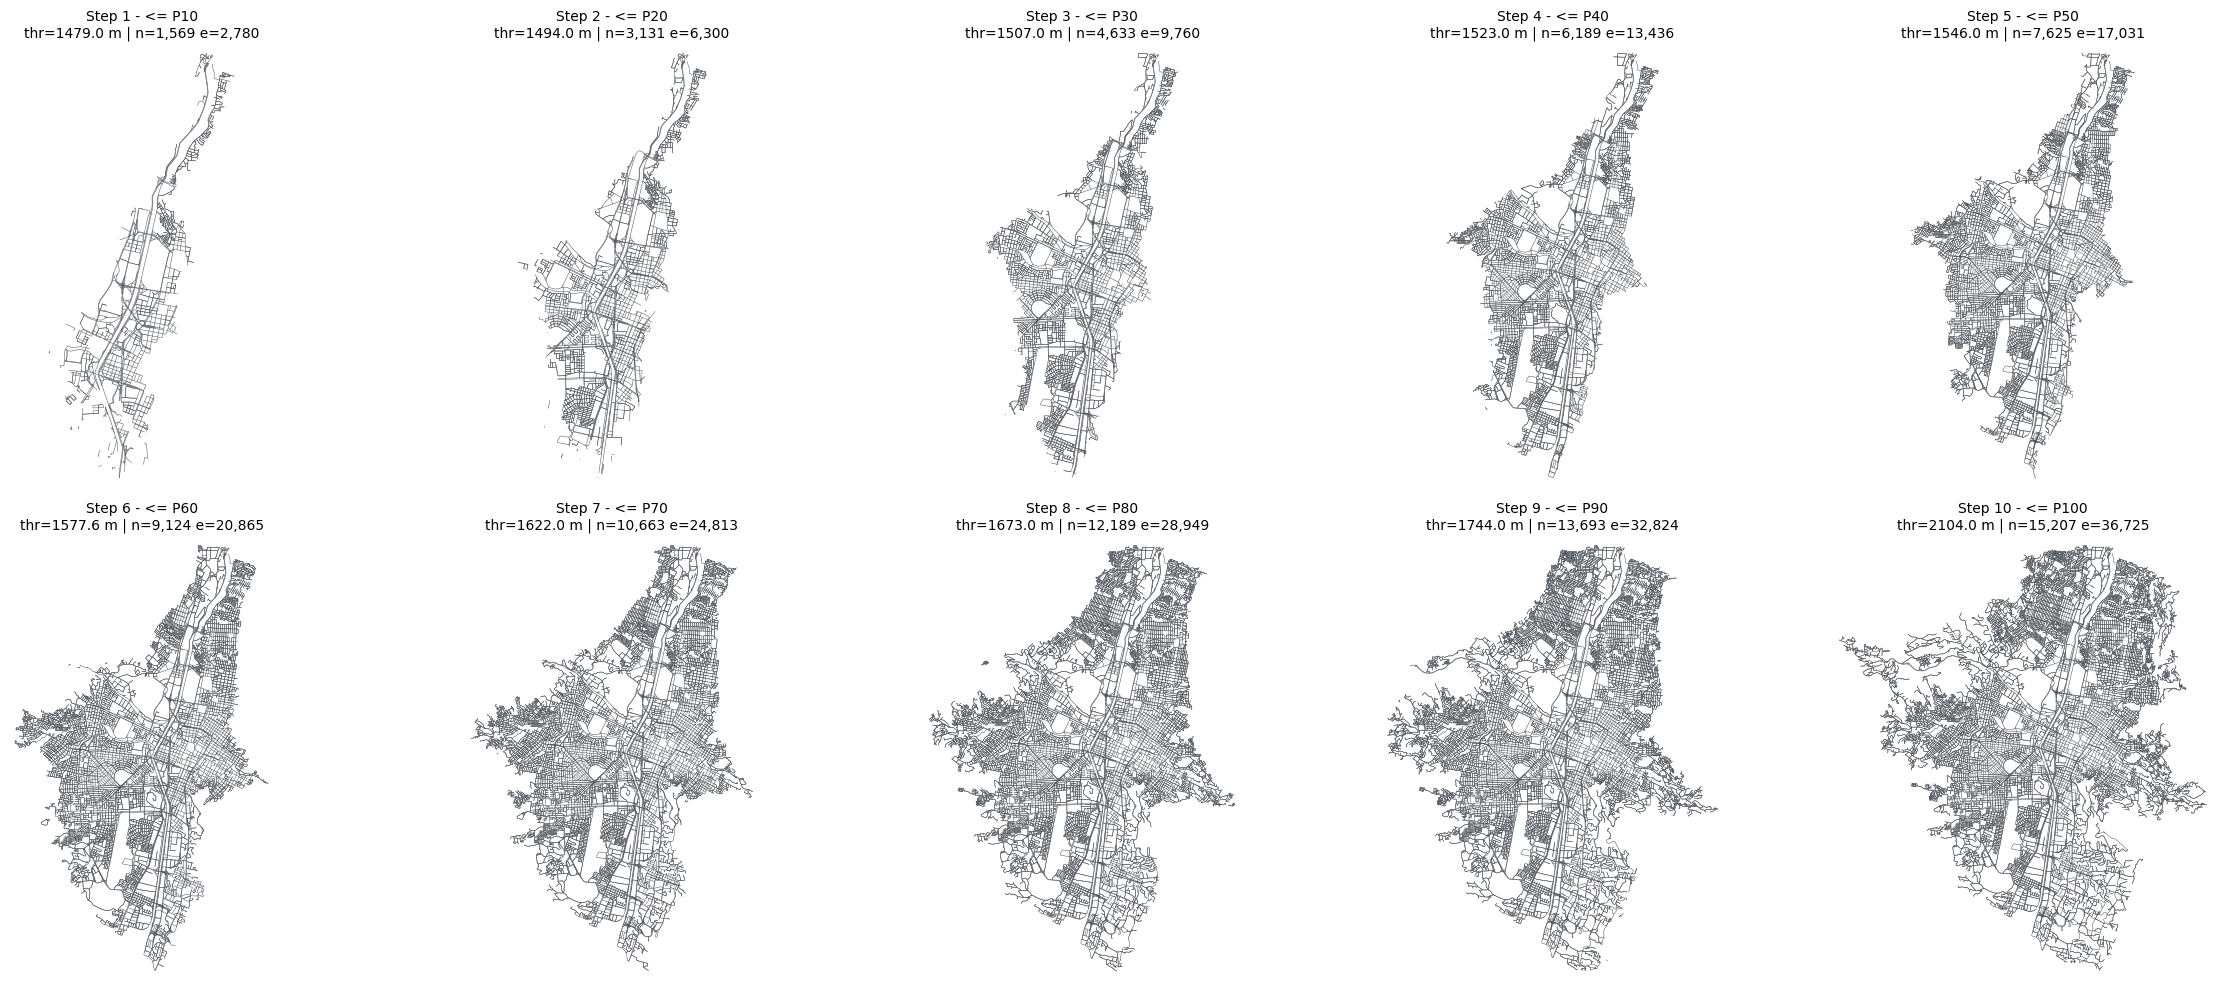

In [6]:
# Plot all 10 filtration steps in a 2x5 grid
fig, axes = plt.subplots(2, 5, figsize=(24, 10))
axes = axes.ravel()

for ax, item in zip(axes, filtration):
    H = item["graph"]
    title = (
        f"Step {item['step']} - <= P{int(item['percentile'])}\n"
        f"thr={item['threshold_m']:.1f} m | n={item['n_nodes']:,} e={item['n_edges']:,}"
    )

    if H.number_of_nodes() == 0:
        ax.set_title(title)
        ax.axis("off")
        continue

    ox.plot_graph(
        H,
        ax=ax,
        show=False,
        close=False,
        node_size=0,
        edge_linewidth=0.35,
        node_color="#0b7285",
        edge_color="#495057",
        bgcolor="white",
    )
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()

plt.tight_layout()
plt.savefig('output.pdf')
plt.show()

Loaded graph: data/medellin_drive_with_elevation.graphml
Nodes: 15207
Edges: 36725


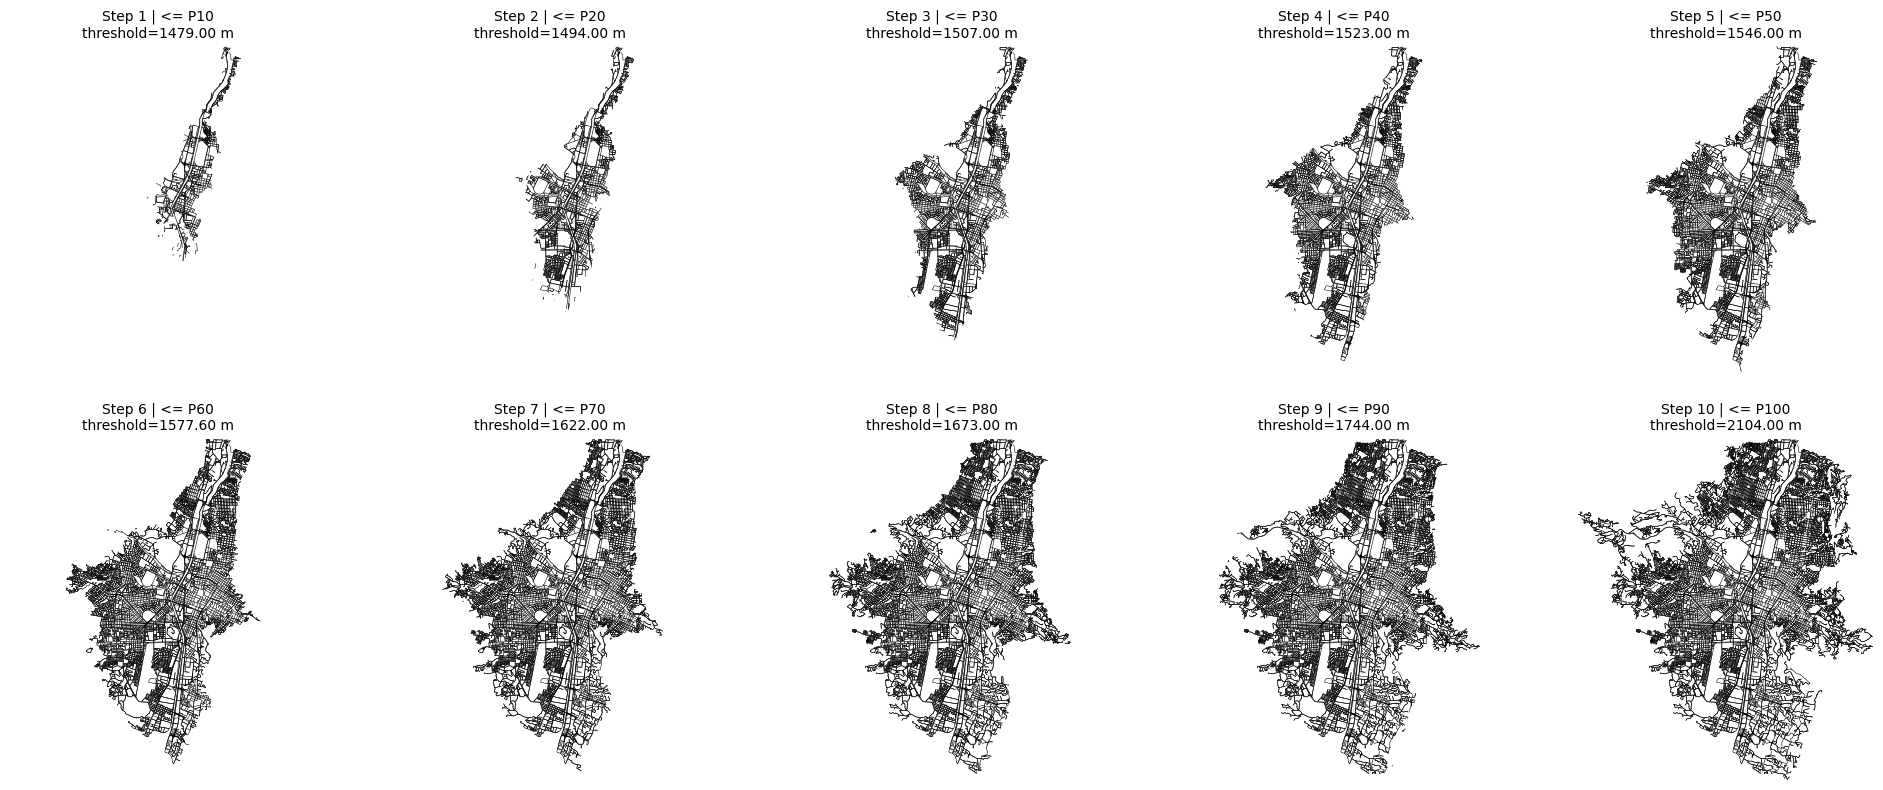


Final graph summary
Nodes: 15207
Edges: 22434

Simplex tree summary
Dimension: 1
Num vertices: 15207
Num simplices: 37641

Finite H1 intervals:
[]

Graph-theoretic diagnostics
Connected components: 1
Cycle rank: 7228

Betti numbers:
[1, 7228]


<Figure size 700x600 with 0 Axes>

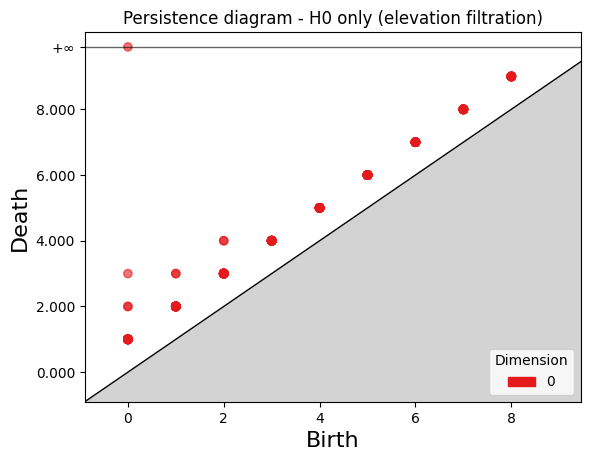

<Figure size 1000x400 with 0 Axes>

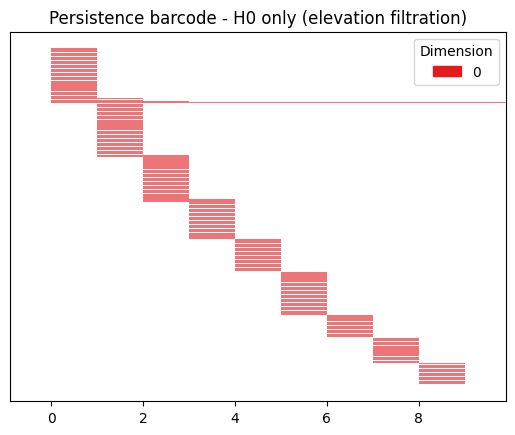

<Figure size 700x600 with 0 Axes>

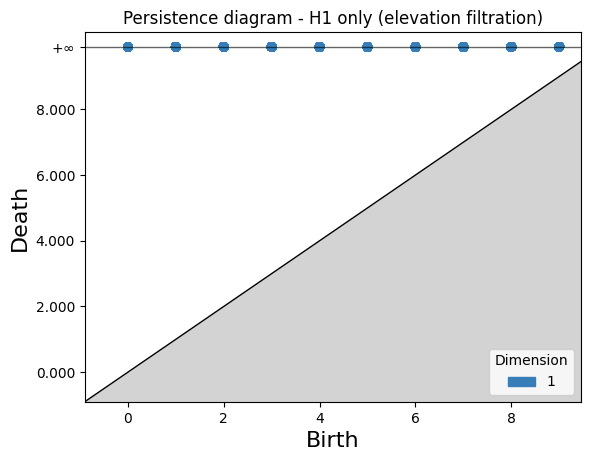

<Figure size 1000x400 with 0 Axes>

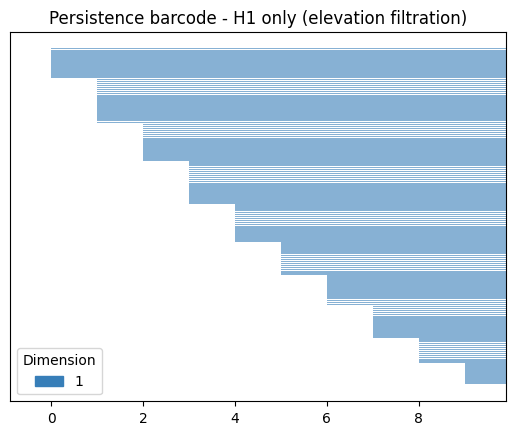


Step-by-step filtration summary

Step 1 -> <= P10 (threshold=1479.00 m)
Nodes: 1569
Edges: 2193
Connected components: 41
Cycle rank: 665

Step 2 -> <= P20 (threshold=1494.00 m)
Nodes: 3131
Edges: 4683
Connected components: 44
Cycle rank: 1596

Step 3 -> <= P30 (threshold=1507.00 m)
Nodes: 4633
Edges: 7023
Connected components: 37
Cycle rank: 2427

Step 4 -> <= P40 (threshold=1523.00 m)
Nodes: 6189
Edges: 9494
Connected components: 31
Cycle rank: 3336

Step 5 -> <= P50 (threshold=1546.00 m)
Nodes: 7625
Edges: 11755
Connected components: 25
Cycle rank: 4155

Step 6 -> <= P60 (threshold=1577.60 m)
Nodes: 9124
Edges: 13955
Connected components: 33
Cycle rank: 4864

Step 7 -> <= P70 (threshold=1622.00 m)
Nodes: 10663
Edges: 16174
Connected components: 18
Cycle rank: 5529

Step 8 -> <= P80 (threshold=1673.00 m)
Nodes: 12189
Edges: 18399
Connected components: 20
Cycle rank: 6230

Step 9 -> <= P90 (threshold=1744.00 m)
Nodes: 13693
Edges: 20443
Connected components: 17
Cycle rank: 6767

Step 

In [8]:
# If needed once:
# !pip install gudhi

import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import gudhi

ox.settings.use_cache = True
ox.settings.log_console = True

# -----------------------------
# LOAD GRAPH
# -----------------------------
graph_path = "data/medellin_drive_with_elevation.graphml"
G = ox.load_graphml(graph_path)

print("Loaded graph:", graph_path)
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

# -----------------------------
# ELEVATION-BASED FILTRATION (10 STEPS)
# -----------------------------
n_steps = 10
percentiles = np.arange(10, 101, 10)  # 10,20,...,100

def to_float(x):
    try:
        val = float(x)
        return val if np.isfinite(val) else np.nan
    except (TypeError, ValueError):
        return np.nan

# node elevations
node_elev = {}
for n, data in G.nodes(data=True):
    e = data.get("elevation_m", data.get("elevation"))
    e = to_float(e)
    if np.isfinite(e):
        node_elev[n] = e

if len(node_elev) == 0:
    raise ValueError("No valid elevation attribute found (expected 'elevation_m' or 'elevation').")

elev_values = np.array(list(node_elev.values()), dtype=float)
thresholds = np.percentile(elev_values, percentiles)  # threshold per step

# Node filtration time: first step where node appears (0..9)
node_filtration = {}
for n, e in node_elev.items():
    t = int(np.searchsorted(thresholds, e, side="left"))
    t = min(t, n_steps - 1)
    node_filtration[n] = t

# -----------------------------
# PREPARE EDGE GDF + FILTRATION FOR PLOTTING
# -----------------------------
edges = ox.graph_to_gdfs(G, nodes=False).copy()

u_idx = edges.index.get_level_values(0)
v_idx = edges.index.get_level_values(1)

# keep only edges whose endpoints have valid elevation
mask = u_idx.isin(node_filtration.keys()) & v_idx.isin(node_filtration.keys())
edges = edges[mask].copy()

u_idx = edges.index.get_level_values(0)
v_idx = edges.index.get_level_values(1)

# Edge appears when both endpoints have appeared
edges["filtration"] = [max(node_filtration[u], node_filtration[v]) for u, v in zip(u_idx, v_idx)]

xmin, ymin, xmax, ymax = edges.total_bounds

# -----------------------------
# PLOT FILTRATION SNAPSHOTS
# -----------------------------
cols = 5
rows = int(np.ceil(n_steps / cols))

fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
axes = np.array(axes).flatten()


for t in range(n_steps):
    ax = axes[t]
    subset = edges[edges["filtration"] <= t]

    if not subset.empty:
        subset.plot(ax=ax, linewidth=0.4, color="black")

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(
        f"Step {t+1} | <= P{(t+1)*10}\nthreshold={thresholds[t]:.2f} m",
        fontsize=10
    )
    ax.set_axis_off()

for j in range(n_steps, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# -----------------------------
# BUILD SIMPLE UNDIRECTED GRAPH
# -----------------------------
# Collapse MultiDiGraph -> simple Graph, keep earliest filtration on parallel edges.
H = nx.Graph()

# add vertices with node filtration
for n, t in node_filtration.items():
    H.add_node(n, filtration=t)

for (u, v, k), row in edges.iterrows():
    t = int(row["filtration"])

    if u == v:
        continue

    if H.has_edge(u, v):
        H[u][v]["filtration"] = min(H[u][v]["filtration"], t)
    else:
        H.add_edge(u, v, filtration=t)

print("\nFinal graph summary")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())

# -----------------------------
# BUILD GUDHI SIMPLEX TREE (1D)
# -----------------------------
st = gudhi.SimplexTree()

node_to_int = {node: i for i, node in enumerate(H.nodes())}
int_to_node = {i: node for node, i in node_to_int.items()}

# Insert vertices
for node, data in H.nodes(data=True):
    st.insert([node_to_int[node]], filtration=float(data["filtration"]))

# Insert edges
for u, v, data in H.edges(data=True):
    st.insert([node_to_int[u], node_to_int[v]], filtration=float(data["filtration"]))

# Ensure filtration consistency
st.make_filtration_non_decreasing()

print("\nSimplex tree summary")
print("Dimension:", st.dimension())
print("Num vertices:", st.num_vertices())
print("Num simplices:", st.num_simplices())

# -----------------------------
# COMPUTE PERSISTENCE
# -----------------------------
diag = st.persistence(
    homology_coeff_field=2,
    persistence_dim_max=True
)

h0 = st.persistence_intervals_in_dimension(0)
h1 = st.persistence_intervals_in_dimension(1)

h1_finite = h1[np.isfinite(h1).all(axis=1)] if len(h1) > 0 else np.empty((0, 2))
print("\nFinite H1 intervals:")
print(h1_finite)

if len(h1_finite) > 0:
    h1_lengths = h1_finite[:, 1] - h1_finite[:, 0]
    print("\nFinite H1 bar lengths:")
    print(h1_lengths)

# -----------------------------
# GRAPH-THEORETIC CHECK
# -----------------------------
c = nx.number_connected_components(H)
m = H.number_of_edges()
n_nodes = H.number_of_nodes()
cycle_rank = m - n_nodes + c

print("\nGraph-theoretic diagnostics")
print("Connected components:", c)
print("Cycle rank:", cycle_rank)

# -----------------------------
# BETTI NUMBERS
# -----------------------------
bettis = st.betti_numbers()
print("\nBetti numbers:")
print(bettis)

# -----------------------------
# PLOT H0 ONLY
# -----------------------------
if len(h0) > 0:
    h0_diag = [(0, (birth, death)) for birth, death in h0]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h0_diag)
    plt.title("Persistence diagram - H0 only (elevation filtration)")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h0_diag)
    plt.title("Persistence barcode - H0 only (elevation filtration)")
    plt.show()
else:
    print("\nNo H0 intervals found.")

# -----------------------------
# PLOT H1 ONLY
# -----------------------------
if len(h1) > 0:
    h1_diag = [(1, (birth, death)) for birth, death in h1]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h1_diag)
    plt.title("Persistence diagram - H1 only (elevation filtration)")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h1_diag)
    plt.title("Persistence barcode - H1 only (elevation filtration)")
    plt.show()
else:
    print("\nNo H1 intervals found.")

# -----------------------------
# STEP-BY-STEP FILTRATION CHECK
# -----------------------------
print("\nStep-by-step filtration summary")
for t in range(n_steps):
    nodes_t = [n for n, d in H.nodes(data=True) if d["filtration"] <= t]
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= t]

    G_t = nx.Graph()
    G_t.add_nodes_from(nodes_t)
    G_t.add_edges_from(edges_t)

    n_t = G_t.number_of_nodes()
    m_t = G_t.number_of_edges()
    c_t = nx.number_connected_components(G_t) if n_t > 0 else 0
    cycle_rank_t = m_t - n_t + c_t if n_t > 0 else 0

    print(f"\nStep {t+1} -> <= P{(t+1)*10} (threshold={thresholds[t]:.2f} m)")
    print("Nodes:", n_t)
    print("Edges:", m_t)
    print("Connected components:", c_t)
    print("Cycle rank:", cycle_rank_t)


In [9]:
import numpy as np
import pandas as pd
import networkx as nx

# Assumes `filtration` already exists (from your 10-step elevation filtration notebook)
rows = []

for f in filtration:
    H = f["graph"]  # subgraph at this step

    # Simple undirected version for cycle-rank formula
    U = nx.Graph(H.to_undirected())
    U.remove_edges_from(nx.selfloop_edges(U))

    n = U.number_of_nodes()
    m = U.number_of_edges()
    c = nx.number_connected_components(U) if n > 0 else 0

    beta1 = (m - n + c) if n > 0 else 0   # number of independent cycles
    cycle_edge_ratio = (beta1 / m) if m > 0 else np.nan

    rows.append({
        "step": f["step"],
        "percentile": f["percentile"],
        "threshold_m": f["threshold_m"],
        "nodes": n,
        "edges": m,
        "beta1_cycles": beta1,
        "cycle_edge_ratio": cycle_edge_ratio,
    })

cycle_edge_df = pd.DataFrame(rows)
cycle_edge_df


,step,percentile,threshold_m,nodes,edges,beta1_cycles,cycle_edge_ratio
0,1,10.0,1479.0,1569,2193,665,0.303238
1,2,20.0,1494.0,3131,4683,1596,0.340807
2,3,30.0,1507.0,4633,7023,2427,0.345579
3,4,40.0,1523.0,6189,9494,3336,0.351380
4,5,50.0,1546.0,7625,11755,4155,0.353467
5,6,60.0,1577.6,9124,13955,4864,0.348549
6,7,70.0,1622.0,10663,16174,5529,0.341845
7,8,80.0,1673.0,12189,18399,6230,0.338605
8,9,90.0,1744.0,13693,20443,6767,0.331018
9,10,100.0,2104.0,15207,22434,7228,0.322190


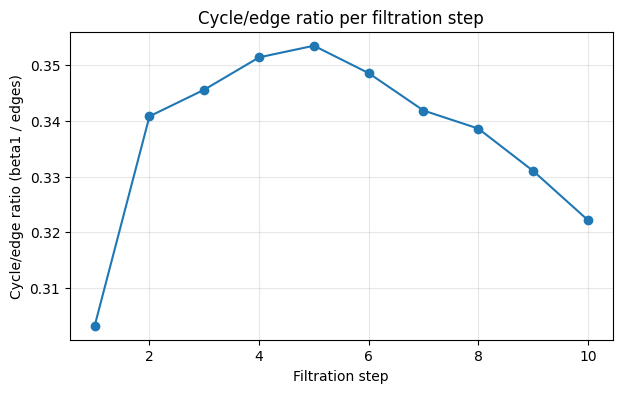

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))
plt.plot(cycle_edge_df["step"], cycle_edge_df["cycle_edge_ratio"], marker="o")
plt.xlabel("Filtration step")
plt.ylabel("Cycle/edge ratio (beta1 / edges)")
plt.title("Cycle/edge ratio per filtration step")
plt.grid(alpha=0.3)
plt.show()


Text(0.5, 1.0, 'When do cycles close? (H1 birth distribution)')

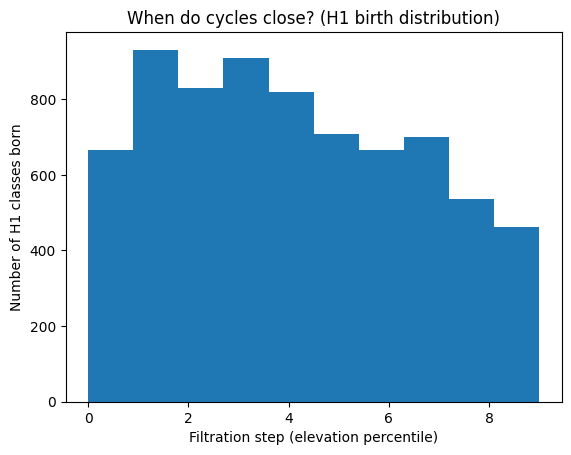

In [11]:
h1_births = h1[:, 0]  # from your gudhi output
# Plot histogram of birth times
plt.hist(h1_births, bins=n_steps)
plt.xlabel("Filtration step (elevation percentile)")
plt.ylabel("Number of H1 classes born")
plt.title("When do cycles close? (H1 birth distribution)")

In [12]:
node_additions = [filtration[t]["n_nodes"] - (filtration[t-1]["n_nodes"] if t > 0 else 0) 
                  for t in range(n_steps)]
h1_births_per_step = [sum(1 for b, _ in h1 if int(b) == t) for t in range(n_steps)]
cycle_per_node_added = [h / n if n > 0 else 0 
                        for h, n in zip(h1_births_per_step, node_additions)]

In [13]:
cycle_per_node_added

[0.4238368387507967,
 0.5960307298335468,
 0.5532623169107856,
 0.5841902313624678,
 0.5703342618384402,
 0.47298198799199465,
 0.43209876543209874,
 0.45937090432503275,
 0.3570478723404255,
 0.3044914134742404]

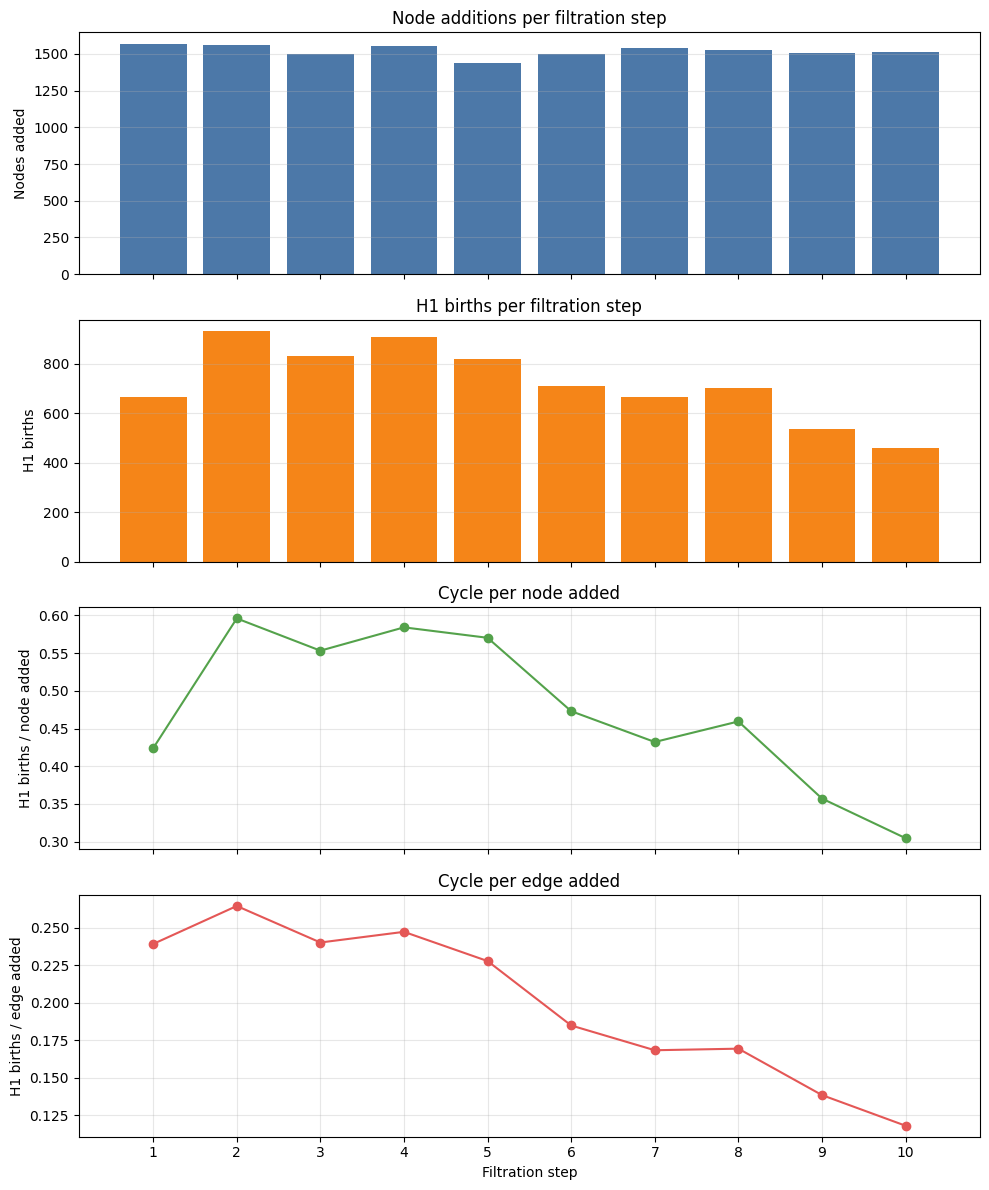

In [14]:
node_additions = [
    filtration[t]["n_nodes"] - (filtration[t - 1]["n_nodes"] if t > 0 else 0)
    for t in range(n_steps)
]

edge_additions = [
    filtration[t]["n_edges"] - (filtration[t - 1]["n_edges"] if t > 0 else 0)
    for t in range(n_steps)
]

if len(h1) > 0:
    h1_births_per_step = [sum(1 for b, _ in h1 if int(b) == t) for t in range(n_steps)]
else:
    h1_births_per_step = [0] * n_steps

cycle_per_node_added = [
    h / n if n > 0 else 0
    for h, n in zip(h1_births_per_step, node_additions)
]

cycle_per_edge_added = [
    h / e if e > 0 else 0
    for h, e in zip(h1_births_per_step, edge_additions)
]

steps = np.arange(1, n_steps + 1)

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

axes[0].bar(steps, node_additions, color="#4c78a8")
axes[0].set_ylabel("Nodes added")
axes[0].set_title("Node additions per filtration step")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(steps, h1_births_per_step, color="#f58518")
axes[1].set_ylabel("H1 births")
axes[1].set_title("H1 births per filtration step")
axes[1].grid(axis="y", alpha=0.3)

axes[2].plot(steps, cycle_per_node_added, marker="o", color="#54a24b")
axes[2].set_ylabel("H1 births / node added")
axes[2].set_title("Cycle per node added")
axes[2].grid(alpha=0.3)

axes[3].plot(steps, cycle_per_edge_added, marker="o", color="#e45756")
axes[3].set_ylabel("H1 births / edge added")
axes[3].set_xlabel("Filtration step")
axes[3].set_title("Cycle per edge added")
axes[3].grid(alpha=0.3)

plt.xticks(steps)
plt.tight_layout()
plt.show()